# Sidorenko--Fischer: histogram recovery (§IV-B)

This is the last missing piece. [encode_m.ipynb](encode_m.ipynb) encodes;
[guruswami_sudan.ipynb](guruswami_sudan.ipynb) list-decodes a single noisy Reed--Solomon
codeword. Neither answers the question the paper is actually about: given a
**superposition** of $t$ hypervectors, recover *which* codewords are in it.

That is §IV-B, *histogram recovery*, and the paper does it with a borrowed algorithm:

> we utilize a Kautz--Singleton decoding algorithm **[26, Alg. 2]**, which is inspired by
> the well-known Guruswami--Sudan list decoding algorithm [9, Sec. 2.2]. It uses
> $M \triangleq dY$ as input

Reference **[26]** is *V. Sidorenko and R. Fischer, "Low-complexity list decoding of
Reed--Solomon coded pulse position modulation."* Note the spelling --- **Fischer**, not
Fisher.

## The whole pipeline, finally end to end

| Stage | Where | This notebook |
|---|---|---|
| message $\to$ hypervector | `encode_m.ipynb` | reused |
| superpose $t$ of them | `encode_m.ipynb` | reused |
| superposition $\to$ histograms | §IV-A | implemented here |
| histograms $\to$ codewords | §IV-B, [26, Alg. 2] | implemented here |

## Why an ordinary list decoder is not enough

A superposition does not hand you one corrupted codeword. It hands you, at each of the
$N$ positions, a **set** of symbols --- the ones contributed by the $t$ superimposed
codewords. That is a *disjunctive* (logical-OR) channel, and it is exactly the
pulse-position-modulation setting [26] was written for.

The trick that makes it tractable: the score $\langle W, M \rangle$ with $M = dY$ assigns
the **same** multiplicity $d$ to every observed symbol. So it is ordinary
Guruswami--Sudan interpolation, just over a larger point set --- every pair
$(x_j, a)$ with $a$ observed at position $j$. Working the counting argument through that
enlarged set reproduces the paper's bound (6) exactly, which is derived below.

Everything here uses $m = 1$ so the histograms are small enough to print and read.

In [1]:
import itertools
import random

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import sage.all__sagemath_modules as _sage_bootstrap    # must precede sage.coding
from sage.coding.grs_code import GeneralizedReedSolomonCode
from sage.coding.guruswami_sudan.gs_decoder import GRSGuruswamiSudanDecoder
from sage.coding.guruswami_sudan.interpolation import gs_interpolation_linalg
from sage.rings.finite_rings.finite_field_constructor import GF

%matplotlib inline
np.set_printoptions(precision=3, suppress=True, linewidth=140)


def load_notebook_defs(path, skip=("plt.show(",)):
    """exec another notebook's code cells, skipping figures and magics.

    The marker is `plt.show(` rather than `plt.subplots`, so that this very
    skip-list does not match the cell it lives in when some *other* loader
    reads this notebook.
    """
    import contextlib, io, json
    nb = json.loads(open(path).read())
    ns = {}
    for cell in nb["cells"]:
        if cell["cell_type"] != "code":
            continue
        src = "".join(cell["source"])
        if any(kw in src for kw in skip):
            continue
        src = "\n".join(("# " + ln) if ln.lstrip()[:1] in ("%", "!") else ln
                        for ln in src.split("\n"))
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(src, path, "exec"), ns)
        except Exception:
            pass
    return ns


enc = load_notebook_defs("encode_m.ipynb")
p, m, K = 7, 1, 2
q = N = p ** m
tab = enc["gf_tables"](p, m)

F = GF(p)                                  # m = 1, so the field is just F_p
points = [F(j) for j in range(N)]          # evaluation points, in our integer order
Rx = F["x"]
CODE = GeneralizedReedSolomonCode(points, K)
# points[i] is the field element whose integer encoding is i, so the inverse map is
# just this dict. int() would do at m = 1 but NOT for m > 1: int() refuses to coerce
# a GF(p^m) element, so every field-element -> integer step goes through FROM_SAGE.
FROM_SAGE = {points[i]: i for i in range(N)}
ROOT_FINDER = GRSGuruswamiSudanDecoder(
    CODE, tau=1, interpolation_alg="LinearAlgebra").rootfinding_algorithm()

print(f"p = {p}, m = {m}, K = {K}  ->  N = {N}, hypervector dim = {p ** (2 * m)}")
print(f"{CODE}")
print(f"u_max from encode_m.ipynb (Thm 1, noiseless) = {enc['u_max'](N, K)}")

# our encoder and Sage's agree, so this is encode_m.ipynb's code
_rng = np.random.default_rng(0)
for _ in range(20):
    u = [int(z) for z in _rng.integers(0, q, K)]
    ours = list(enc["reed_solomon_encode"](u, p, m, tab))
    theirs = [int(Rx(list(u))(x)) for x in points]
    assert ours == theirs, (u, ours, theirs)
print("reed_solomon_encode agrees with Sage's evaluation on 20/20 messages")

p = 7, m = 1, K = 2  ->  N = 7, hypervector dim = 49
[7, 2, 6] Reed-Solomon Code over GF(7)
u_max from encode_m.ipynb (Thm 1, noiseless) = 6
reed_solomon_encode agrees with Sage's evaluation on 20/20 messages


## Step 1 --- Kautz--Singleton: one-hot the codeword

A Kautz--Singleton codeword is a Reed--Solomon codeword written as a binary
$p^m \times N$ matrix: column $j$ is the indicator of the symbol $c_j$. So each column has
exactly one 1, and $\lvert \mathrm{supp}(W) \rvert = N$.

This is what turns "which symbols appeared" into a set-union problem: superimposing
codewords over the disjunctive channel is the OR of their matrices.

In [2]:
def ks_matrix(codeword, q):
    """Kautz-Singleton: one-hot each RS symbol into a column. q x N, binary."""
    W = np.zeros((q, len(codeword)), dtype=int)
    for j, a in enumerate(codeword):
        W[int(a), j] = 1
    return W


demo_msg = [2, 1]
demo_cw = enc["reed_solomon_encode"](demo_msg, p, m, tab)
W = ks_matrix(demo_cw, q)
print(f"message {demo_msg}  ->  RS codeword {list(demo_cw)}")
print(f"\nW(c), rows = symbol 0..{q - 1}, columns = position 0..{N - 1}:")
print(W)
assert W.sum() == N and (W.sum(axis=0) == 1).all()
print(f"\nexactly one 1 per column, so |supp(W)| = N = {N}")

message [2, 1]  ->  RS codeword [2, 3, 4, 5, 6, 0, 1]

W(c), rows = symbol 0..6, columns = position 0..6:
[[0 0 0 0 0 1 0]
 [0 0 0 0 0 0 1]
 [1 0 0 0 0 0 0]
 [0 1 0 0 0 0 0]
 [0 0 1 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 0 1 0 0]]

exactly one 1 per column, so |supp(W)| = N = 7


## Step 2 --- §IV-A: histograms out of the superposition

The superposition $s = \sum_i \phi(f_{\mathrm{Had}}(c_i))$ splits into $N$ blocks of
length $N$, and block $j$ is exactly $H h_j$ where $h_j$ is the histogram of symbols at
position $j$. Since $H^\dagger H = N I$ (verified in `encode_m.ipynb`), inverting is one
matrix multiply:

$$h_j \;=\; \tfrac{1}{N} H^\dagger s_j$$

The paper describes §IV-A as lattice decoding, which it is in the presence of noise ---
the rounding step is the lattice decoder. Noiselessly the inverse is exact, which is what
the assertion below checks.

In [3]:
def histograms_from_superposition(sup, p, m, tables=None):
    """Section IV-A. Invert the Hadamard block-wise: h_j = (1/N) H^dagger s_j.

    Returns a q x N integer matrix; entry (a, j) counts how many of the
    superimposed codewords carry symbol a at position j.
    """
    H = enc["hadamard_matrix"](p, m, tables)
    N = p ** m
    blocks = np.asarray(sup).reshape(N, N).T          # column j = block j
    return np.rint((H.conj().T @ blocks).real / N).astype(int)


def superpose(messages, p, m, tables=None):
    return sum(enc["histo_encode"](u, p, m, tables) for u in messages)


rng = random.Random(0)
T = 4
messages, seen = [], set()
while len(messages) < T:
    u = tuple(rng.randrange(q) for _ in range(K))
    if u not in seen:
        seen.add(u)
        messages.append(list(u))
codewords = [list(enc["reed_solomon_encode"](u, p, m, tab)) for u in messages]

sup = superpose(messages, p, m, tab)
hist = histograms_from_superposition(sup, p, m, tab)

print(f"superimposed t = {T} messages: {messages}")
print(f"their RS codewords:")
for u, c in zip(messages, codewords):
    print(f"   {u} -> {c}")
print(f"\nsuperposition lives in C^{sup.shape[0]}; recovered histograms (q x N):")
print(hist)

truth = np.array([[sum(1 for c in codewords if c[j] == a) for j in range(N)]
                  for a in range(q)])
assert np.array_equal(hist, truth), "IV-A inversion must be exact when noiseless"
assert (hist.sum(axis=0) == T).all(), "every column must sum to t"
print(f"\nmatches the true histograms exactly: True")
print(f"every column sums to t = {T}, which is how t is read off the data")

superimposed t = 4 messages: [[6, 3], [0, 2], [4, 3], [3, 6]]
their RS codewords:
   [6, 3] -> [6, 2, 5, 1, 4, 0, 3]
   [0, 2] -> [0, 2, 4, 6, 1, 3, 5]
   [4, 3] -> [4, 0, 3, 6, 2, 5, 1]
   [3, 6] -> [3, 2, 1, 0, 6, 5, 4]

superposition lives in C^49; recovered histograms (q x N):
[[1 1 0 1 0 1 0]
 [0 0 1 1 1 0 1]
 [0 3 0 0 1 0 0]
 [1 0 1 0 0 1 1]
 [1 0 1 0 1 0 1]
 [0 0 1 0 0 2 1]
 [1 0 0 2 1 0 0]]

matches the true histograms exactly: True
every column sums to t = 4, which is how t is read off the data


## Step 3 --- the disjunctive channel, and the score

Throw away the counts and keep only *which* symbols appeared:

$$y_{a,j} = 1 \iff h_{a,j} > 0, \qquad M \triangleq dY$$

That is the disjunctive channel --- $Y$ is the OR of the $t$ Kautz--Singleton matrices.
The score of a candidate codeword is

$$\langle W(c), M \rangle \;=\; d \cdot \#\{\,j : c_j \text{ was observed at } j\,\}$$

Two facts make the whole scheme work, and both are checked below:

- Every **superimposed** codeword scores the maximum $dN$, since $\mathrm{supp}(W^{(i)})
  \subseteq \mathrm{supp}(Y)$ by construction.
- Every **other** codeword scores at most $dt(K-1)$ --- that is Lemma 2, which follows
  from two distinct Reed--Solomon codewords agreeing in at most $K-1$ places.

So thresholding at $dN$ separates them exactly when $t(K-1) < N$, i.e.
$t < \frac{N}{K-1}$ --- the second term of the paper's bound (6).

In [4]:
def support_matrix(hist):
    """Y: the disjunctive (OR) channel output. y[a,j] = 1 iff h[a,j] > 0."""
    return (hist > 0).astype(int)


def score(codeword, M):
    """<W(c), M> -- sum M over the one-hot positions of c."""
    return sum(int(M[int(a), j]) for j, a in enumerate(codeword))


def codeword_of(f, points, from_sage):
    """Evaluate f at every point, in our integer encoding. Works for any m."""
    return [from_sage[f(x)] for x in points]


def message_of(f, K, from_sage):
    """Coefficients of f as a length-K message, in our integer encoding.

    Goes through from_sage rather than int(): a GF(p^m) element with m > 1
    cannot be coerced to an integer at all.
    """
    zero = f.base_ring().zero()
    coeffs = list(f.list()) + [zero] * (K - len(f.list()))
    return [from_sage[c] for c in coeffs]


d = 1
Y = support_matrix(hist)
M = d * Y
print(f"Y (disjunctive channel output), d = {d}:")
print(Y)
print(f"\nsupport sizes per position |S_j| = {list(Y.sum(axis=0))}, "
      f"total n_P = {int(Y.sum())}")

# Y really is the OR of the individual Kautz-Singleton matrices
assert np.array_equal(Y, np.clip(sum(ks_matrix(c, q) for c in codewords), 0, 1))
print("Y is the OR of the t Kautz-Singleton matrices: True")

print(f"\nscores  (maximum possible is d*N = {d * N})")
for u, c in zip(messages, codewords):
    sc = score(c, M)
    print(f"   superimposed {u} -> {c}  score {sc}  == d*N: {sc == d * N}")
    assert sc == d * N

worst = 0
for coeffs in itertools.product(range(q), repeat=K):
    c = [int(Rx(list(coeffs))(x)) for x in points]
    if c not in codewords:
        worst = max(worst, score(c, M))
print(f"\nLemma 2: every other codeword scores <= d*t*(K-1) = {d * T * (K - 1)}")
print(f"   worst score among the {q ** K - T} spurious codewords: {worst}")
assert worst <= d * T * (K - 1)
print(f"   so the threshold d*N = {d * N} separates them: {worst < d * N}")

Y (disjunctive channel output), d = 1:
[[1 1 0 1 0 1 0]
 [0 0 1 1 1 0 1]
 [0 1 0 0 1 0 0]
 [1 0 1 0 0 1 1]
 [1 0 1 0 1 0 1]
 [0 0 1 0 0 1 1]
 [1 0 0 1 1 0 0]]

support sizes per position |S_j| = [4, 2, 4, 3, 4, 3, 4], total n_P = 24
Y is the OR of the t Kautz-Singleton matrices: True

scores  (maximum possible is d*N = 7)
   superimposed [6, 3] -> [6, 2, 5, 1, 4, 0, 3]  score 7  == d*N: True
   superimposed [0, 2] -> [0, 2, 4, 6, 1, 3, 5]  score 7  == d*N: True
   superimposed [4, 3] -> [4, 0, 3, 6, 2, 5, 1]  score 7  == d*N: True
   superimposed [3, 6] -> [3, 2, 1, 0, 6, 5, 4]  score 7  == d*N: True

Lemma 2: every other codeword scores <= d*t*(K-1) = 4
   worst score among the 45 spurious codewords: 4
   so the threshold d*N = 7 separates them: True


## Step 4 --- [26, Alg. 2]: the decoder

With $M = dY$ uniform on the support, the algorithm *is* Guruswami--Sudan interpolation
over the enlarged point set

$$P \;=\; \{\,(x_j, a) \;:\; y_{a,j} = 1 \,\}, \qquad n_P = \lvert P \rvert = \textstyle\sum_j |S_j|$$

with multiplicity $d$ at every point. The three stages are the same as in
`guruswami_sudan.ipynb`:

1. **Interpolate** $Q(x,y)$ vanishing to multiplicity $d$ at all $n_P$ points, with
   $(1, K-1)$-weighted degree $< Nd$.
2. **Root-find** every $f$ with $\deg f < K$ such that $(y - f(x)) \mid Q$.

Those two *are* Algorithm 2, and that is all of it --- **Algorithm 2 has no filtering
step**. The third stage,

3. **Filter** by score: keep those with $\langle W, M \rangle = dN$,

is `histo.pdf`'s own addition on top: *"apply the Kautz--Singleton decoding algorithm
[26, Alg. 2] on $M$ [...] Then, reject any codeword $\bar W$ such that
$\langle \bar W, M\rangle < dN$."* The code keeps them as two functions,
`ks_algorithm_2` and `ks_list_decode`, so the boundary between the borrowed algorithm and
the paper's use of it stays visible.

Stage 1's degree budget is what forces the guarantee. If $f$ agrees at $A$ positions then
$Q(x, f(x))$ is divisible by $(x - x_j)^d$ at each, so it has $\ge Ad$ roots; if the
weighted degree is below $Nd$ and $A = N$, it must vanish identically, so $f$ *must* appear
as a $y$-root. Sage's `gs_interpolation_linalg` sets the budget to
$(n_P - \tau) \cdot d$, so passing $\tau = n_P - N + 1$ gives exactly $(N-1)d < Nd$.

In [5]:
def ks_algorithm_2(Y, d, p, m, K, points, root_finder, agree=None, ell_max=40):
    """Sidorenko-Fischer Algorithm 2, as written. Returns (candidates, n_P, ell).

    Their two steps, and nothing else:
      1. Interpolation -- a nontrivial p(x,y) of low (1, K-1)-weighted degree
         passing through every (beta_j, alpha_i) with m_{i,j} != 0, with
         multiplicity m_{i,j}.  Here M = d*Y, so the multiplicity is a uniform d
         on the support of Y.
      2. Factorization -- all factors y - f(x) with deg f < K.

    Algorithm 2 has NO filtering step; it returns the whole list. The rejection
    step lives in ks_list_decode below, because it is histo.pdf's addition, not
    theirs.

    One deliberate deviation: their step 1 asks for the polynomial of *minimal*
    weighted degree. We instead fix the budget at agree * d - 1 and take any
    nonzero solution. That is what the guarantee actually needs -- a codeword
    with agreement >= agree scores >= agree*d, which exceeds the budget, so
    Q(x, f(x)) must vanish identically. Minimality is just the natural way to
    obtain such a bound, not a requirement of the argument.

    agree is the guaranteed agreement level, i.e. their (n - tau): noiselessly
    N, and N - s when s histogram columns are corrupted.
    """
    N = p ** m
    if agree is None:
        agree = N
    P = [(points[j], points[int(a)])
         for j in range(N) for a in range(Y.shape[0]) if Y[a, j]]
    # Sage's budget is EXCLUSIVE -- _monomial_list keeps weighted degrees strictly
    # below (n_P - tau)*d -- so tau = n_P - agree gives degrees <= agree*d - 1.
    # An earlier version used n_P - agree + 1 here, capping at (agree-1)*d, which
    # is needlessly tight for d > 1: at t=6, d=2 it made the system overdetermined
    # (91 monomials vs C(M)=93 constraints) and lost codewords that SF Theorem 1
    # guarantees. agree*d - 1 is the largest budget the argument permits.
    tau = len(P) - agree
    for ell in range(2, ell_max):
        try:
            Q = gs_interpolation_linalg(P, tau, (d, ell), K - 1)
        except (IndexError, ValueError):
            continue                          # no nonzero kernel yet; widen ell
        return list(root_finder(Q, maxd=K - 1)), len(P), ell
    raise RuntimeError(f"no interpolation polynomial found up to ell = {ell_max}")


def ks_list_decode(Y, d, p, m, K, points, root_finder, agree=None, ell_max=40,
                   from_sage=None):
    """histo.pdf Section IV-B: run Algorithm 2, then reject the low scorers.

    The paper's words: "apply the Kautz-Singleton decoding algorithm [26, Alg. 2]
    on M to obtain a polynomial-size list of candidate codewords. Then, reject
    any codeword W such that <W, M> < dN, and output the remaining codewords."

    from_sage maps a field element to its integer encoding; it defaults to the
    one implied by `points`. Needed because scoring a candidate means indexing
    rows of Y by symbol, and a GF(p^m) element is not an integer.
    """
    N = p ** m
    if agree is None:
        agree = N
    if from_sage is None:
        from_sage = {points[i]: i for i in range(N)}
    cands, n_P, ell = ks_algorithm_2(Y, d, p, m, K, points, root_finder,
                                     agree=agree, ell_max=ell_max)
    kept = [f for f in cands
            if score(codeword_of(f, points, from_sage), d * Y) >= d * agree]
    return kept, n_P, ell


raw, n_P, ell = ks_algorithm_2(Y, d, p, m, K, points, ROOT_FINDER)
found, _, _ = ks_list_decode(Y, d, p, m, K, points, ROOT_FINDER)
print(f"interpolated over n_P = {n_P} points with multiplicity d = {d}, ell = {ell}")
print(f"Algorithm 2 alone returned {len(raw)} candidate(s); "
      f"histo's rejection step keeps {len(found)}")
print(f"recovered {len(found)} codeword(s):\n")

recovered = []
for f in found:
    cw = codeword_of(f, points, FROM_SAGE)
    msg = message_of(f, K, FROM_SAGE)
    recovered.append(msg)
    print(f"   f(x) = {str(f):<18} message {msg}  codeword {cw}")

assert sorted(recovered) == sorted(messages), (sorted(recovered), sorted(messages))
print(f"\nexactly the t = {T} superimposed messages, nothing else: True")
print("that is the full chain: hypervector superposition -> histograms -> codewords.")

interpolated over n_P = 24 points with multiplicity d = 1, ell = 4
Algorithm 2 alone returned 4 candidate(s); histo's rejection step keeps 4
recovered 4 codeword(s):

   f(x) = 2*x                message [0, 2]  codeword [0, 2, 4, 6, 1, 3, 5]
   f(x) = 3*x + 6            message [6, 3]  codeword [6, 2, 5, 1, 4, 0, 3]
   f(x) = 3*x + 4            message [4, 3]  codeword [4, 0, 3, 6, 2, 5, 1]
   f(x) = 6*x + 3            message [3, 6]  codeword [3, 2, 1, 0, 6, 5, 4]

exactly the t = 4 superimposed messages, nothing else: True
that is the full chain: hypervector superposition -> histograms -> codewords.


## The role of $d$ (Remark 1)

$d$ looks redundant --- $M = dY$ is just a scaled $Y$, and scaling cannot change which
codeword scores highest. But it changes the *interpolation budget*, and that is what sets
how large $t$ can be.

Counting monomials against constraints: $n_P \cdot \frac{d(d+1)}{2}$ linear conditions
against roughly $\frac{(Nd)^2}{2(K-1)}$ coefficients, and $n_P \le tN$, gives

$$t \;<\; \frac{d}{d+1}\cdot\frac{N}{K-1}$$

Combined with the filtering condition $t < \frac{N}{K-1}$ from Lemma 2, that is the
paper's bound (6):

$$t \;\le\; \min\left\{\left\lfloor \frac{d}{d+1}\cdot\frac{N}{K-1}\right\rfloor,\;
  \left\lfloor\frac{N-1}{K-1}\right\rfloor\right\}$$

The factor $\frac{d}{d+1}$ rises to 1 as $d$ grows, which is Remark 1: raising $d$ buys a
larger $t$, and the price is a bigger linear system and a longer output list.

In [6]:
def bound_6(N, K, d):
    """The paper's equation (6)."""
    return min(int(d / (d + 1) * N / (K - 1)), (N - 1) // (K - 1))


def random_distinct_messages(t, q, K, seed):
    r = random.Random(seed)
    out, seen = [], set()
    while len(out) < t:
        u = tuple(r.randrange(q) for _ in range(K))
        if u not in seen:
            seen.add(u)
            out.append(list(u))
    return out


def recovers(t, d, seed=0):
    """Does IV-B recover exactly the t superimposed codewords?"""
    msgs = random_distinct_messages(t, q, K, seed)
    hh = histograms_from_superposition(superpose(msgs, p, m, tab), p, m, tab)
    try:
        got, _, _ = ks_list_decode(support_matrix(hh), d, p, m, K, points, ROOT_FINDER)
    except RuntimeError:
        return False
    rec = [message_of(f, K, FROM_SAGE) for f in got]
    return sorted(rec) == sorted(msgs)


DS = [1, 2, 3, 4]
print(f"{'d':>3} {'bound (6)':>10} {'max t recovered':>16}")
print("-" * 33)
measured = []
for dd in DS:
    best = 0
    for t in range(2, (N - 1) // (K - 1) + 2):
        if recovers(t, dd):
            best = t
        else:
            break
    measured.append(best)
    print(f"{dd:>3} {bound_6(N, K, dd):>10} {best:>16}")
print("\nTwo things to read carefully here.")
print("  1. Bound (6) is SUFFICIENT, not tight -- recovery survives a little past it.")
print("     What matters is the trend: larger d, larger t, exactly as Remark 1 says.")
print(f"  2. 'measured' exceeds the strength ceiling {(N - 1) // (K - 1)} at larger d,")
print("     which is not a contradiction. The strength is a WORST-CASE guarantee: it")
print("     says some collection of that many codewords is unrecoverable, not that")
print("     every one is. These are single random draws, and a random collection of 7")
print("     usually does decode. Example 2 below is the adversarial collection that")
print("     does not -- and its existence is what caps the guarantee.")

  d  bound (6)  max t recovered
---------------------------------
  1          3                6


  2          4                7


  3          5                7


  4          5                7

Two things to read carefully here.
  1. Bound (6) is SUFFICIENT, not tight -- recovery survives a little past it.
     What matters is the trend: larger d, larger t, exactly as Remark 1 says.
  2. 'measured' exceeds the strength ceiling 6 at larger d,
     which is not a contradiction. The strength is a WORST-CASE guarantee: it
     says some collection of that many codewords is unrecoverable, not that
     every one is. These are single random draws, and a random collection of 7
     usually does decode. Example 2 below is the adversarial collection that
     does not -- and its existence is what caps the guarantee.


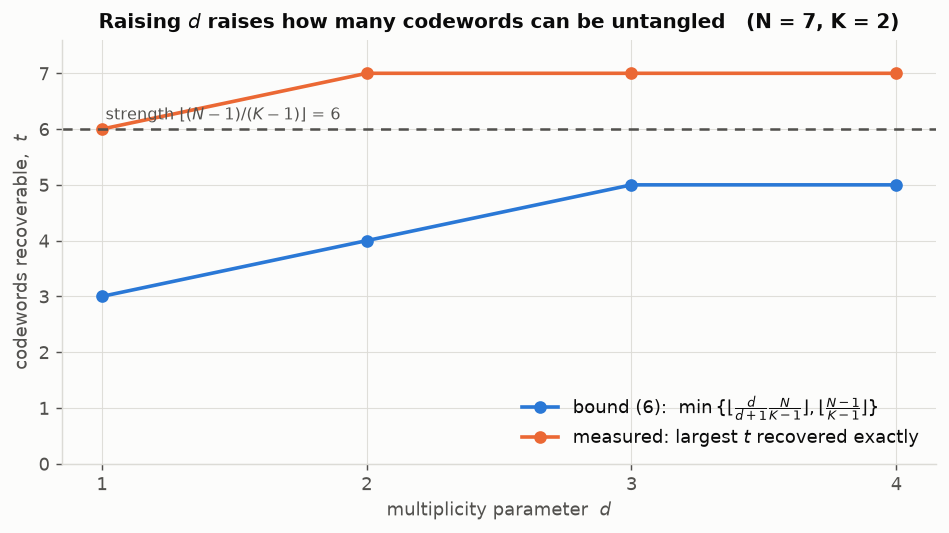

In [7]:
MODE = "light"
PALETTE = {
    "light": {"surface": "#fcfcfb", "ink": "#0b0b0b", "ink2": "#52514e",
              "grid": "#dcdbd6", "series": ["#2a78d6", "#eb6834", "#1baf7a"]},
    "dark":  {"surface": "#1a1a19", "ink": "#ffffff", "ink2": "#c3c2b7",
              "grid": "#3a3a38", "series": ["#3987e5", "#d95926", "#199e70"]},
}
PAL = PALETTE[MODE]
mpl.rcParams.update({
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"],
    "savefig.facecolor": PAL["surface"],
    "text.color": PAL["ink"], "axes.labelcolor": PAL["ink2"],
    "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"],
    "axes.edgecolor": PAL["grid"], "grid.color": PAL["grid"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.linewidth": 0.6, "grid.alpha": 0.9,
    "lines.linewidth": 2.0, "lines.markersize": 6,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 130, "savefig.dpi": 130,
})
import os
os.makedirs("figures", exist_ok=True)

ceiling = (N - 1) // (K - 1)
fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.plot(DS, [bound_6(N, K, dd) for dd in DS], color=PAL["series"][0], marker="o",
        label="bound (6):  $\\min\\{\\lfloor \\frac{d}{d+1}\\frac{N}{K-1}\\rfloor, "
              "\\lfloor\\frac{N-1}{K-1}\\rfloor\\}$")
ax.plot(DS, measured, color=PAL["series"][1], marker="o",
        label="measured: largest $t$ recovered exactly")
ax.axhline(ceiling, color=PAL["ink2"], linestyle=(0, (4, 3)), linewidth=1.4)
ax.annotate(f"strength $\\lfloor (N-1)/(K-1)\\rfloor$ = {ceiling}", (DS[0], ceiling),
            xytext=(2, 5), textcoords="offset points", color=PAL["ink2"], fontsize=9)
ax.set_xlabel("multiplicity parameter  $d$")
ax.set_ylabel("codewords recoverable,  $t$")
ax.set_xticks(DS)
ax.set_ylim(0, ceiling + 1.6)
ax.set_title(f"Raising $d$ raises how many codewords can be untangled"
             f"   (N = {N}, K = {K})")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("figures/sf_t_vs_d.png", bbox_inches="tight")
plt.show()

## Example 2 --- why $t \le \lfloor \frac{N-1}{K-1}\rfloor$ cannot be beaten

The dashed ceiling in that figure is the Kautz--Singleton **strength**, and it is not an
artefact of the algorithm --- it is information-theoretic. The paper's Example 2 exhibits
two different sets of $7$ codewords over $\mathbb{F}_7$ with *identical* histograms:

$$\{\alpha \cdot \mathbf{1}\}_{\alpha \in \mathbb{F}_7}
  \qquad\text{and}\qquad
  \{\alpha \cdot \mathbf{1} + (0,1,\ldots,6)\}_{\alpha \in \mathbb{F}_7}$$

No algorithm can tell them apart, because the input is the same. Reproduced below.

This is what the dashed ceiling means, and it is worth being precise about: the strength
is a **worst-case** guarantee. It does not say every collection of $7$ codewords is
unrecoverable --- the sweep above decoded random 7-element collections fine at $d \ge 3$.
It says *some* collection of $7$ is unrecoverable, and the one below is it. A guarantee
has to cover the worst case, so the ceiling sits at $6$.

In [8]:
A = [[int(F(al)) for _ in range(N)] for al in range(N)]            # {alpha * 1}
B = [[int(F(al) + F(j)) for j in range(N)] for al in range(N)]     # {alpha * 1 + (0..6)}
assert all(cw in [[int(Rx(list(c))(x)) for x in points]
                  for c in itertools.product(range(q), repeat=K)] for cw in A + B)

YA = np.clip(sum(ks_matrix(c, q) for c in A), 0, 1)
YB = np.clip(sum(ks_matrix(c, q) for c in B), 0, 1)
print(f"collection A = {{alpha * 1}}          : {len(A)} codewords")
print(f"collection B = {{alpha * 1 + (0..6)}} : {len(B)} codewords")
print(f"\nA and B are disjoint sets of codewords: {not any(c in B for c in A)}")
print(f"but their disjunctive outputs are identical: {np.array_equal(YA, YB)}")
print(f"and Y is all-ones: {(YA == 1).all()}")
print("\nY (both collections):")
print(YA)

# with Y all-ones every codeword scores the maximum, so nothing can be filtered
scores = [score([int(Rx(list(c))(x)) for x in points], 1 * YA)
          for c in itertools.product(range(q), repeat=K)]
print(f"\nall {len(scores)} codewords score d*N = {N}: {all(s == N for s in scores)}")
print(f"so the filter keeps all {len(scores)} of them -- t = {N} is unrecoverable,")
print(f"which is why the ceiling is (N-1)/(K-1) = {(N - 1) // (K - 1)}, not N.")

collection A = {alpha * 1}          : 7 codewords
collection B = {alpha * 1 + (0..6)} : 7 codewords

A and B are disjoint sets of codewords: True
but their disjunctive outputs are identical: True
and Y is all-ones: True

Y (both collections):
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]

all 49 codewords score d*N = 7: True
so the filter keeps all 49 of them -- t = 7 is unrecoverable,
which is why the ceiling is (N-1)/(K-1) = 6, not N.


## Noisy histograms (§IV-B2)

§IV-A is exact only when the superposition is clean. With noise some histograms come out
wrong, and the paper handles it with two error measures: $e_1$, how many histogram columns
are wrong, and $e_2$, the worst $\ell_1$ deviation of any column.

The preprocessing is a neat trick worth showing. Every column of a correct $H$ sums to
$t$, so a **majority vote over the column sums** recovers $t$ even without knowing it in
advance; any column that disagrees is known-bad and gets zeroed. That converts unknown
corruption into known erasures, which the score threshold tolerates by dropping from $dN$
to $d(N-s)$.

In [9]:
def preprocess_noisy(hist_noisy):
    """Section IV-B2. Majority-vote the column sums to get t, zero the disagreeing
    columns. Returns (cleaned histograms, t, indices zeroed)."""
    sums = hist_noisy.sum(axis=0)
    t = int(np.bincount(sums).argmax())                 # majority vote
    bad = [j for j in range(hist_noisy.shape[1]) if sums[j] != t]
    cleaned = hist_noisy.copy()
    cleaned[:, bad] = 0
    return cleaned, t, bad


T2 = 3
msgs2 = random_distinct_messages(T2, q, K, seed=5)
hist2 = histograms_from_superposition(superpose(msgs2, p, m, tab), p, m, tab)

rng2 = random.Random(1)
noisy = hist2.copy()
corrupted = sorted(rng2.sample(range(N), 2))            # e_1 = 2 bad columns
for j in corrupted:
    a, b = rng2.sample(range(q), 2)
    noisy[a, j] += 1                                    # e_2 = 2 in l_1
    noisy[b, j] = max(0, noisy[b, j] - 1)

cleaned, t_hat, zeroed = preprocess_noisy(noisy)
print(f"t = {T2}, corrupted columns {corrupted}")
print(f"column sums of the noisy histograms: {list(noisy.sum(axis=0))}")
print(f"majority vote recovers t = {t_hat}  (correct: {t_hat == T2})")
print(f"columns zeroed as known-bad: {zeroed}")

# s is the error-model bound e_1 <= s on how many columns are WRONG. Note the
# majority vote only detects the ones whose column sum changed -- a corruption
# that moves mass within a column keeps the sum at t and slips through, so s
# must come from the noise model, not from len(zeroed).
s_err = len(corrupted)
Y2 = support_matrix(cleaned)
print(f"\nerror model: e_1 <= s = {s_err} wrong columns, so the score threshold")
print(f"relaxes from d*N = {3 * N} to d*(N - s) = {3 * (N - s_err)}")
got2, nP2, ell2 = ks_list_decode(Y2, 3, p, m, K, points, ROOT_FINDER,
                                 agree=N - s_err)
kept2 = [f for f in got2]
rec2 = [message_of(f, K, FROM_SAGE) for f in kept2]
print(f"\ndecoding the cleaned histograms (d = 3, n_P = {nP2}, ell = {ell2}):")
for u in sorted(rec2):
    print(f"   recovered {u}{'  <- superimposed' if u in msgs2 else '  (spurious)'}")
assert all(u in rec2 for u in msgs2), "all superimposed messages must survive"
print(f"\nall {T2} superimposed messages recovered despite {len(corrupted)} bad "
      f"histogram columns: True")
spurious = [u for u in rec2 if u not in msgs2]
print(f"spurious survivors: {len(spurious)} -- the relaxed threshold admits more,")
print(f"which is the cost of noise tolerance (Lemma 2 still caps them at "
      f"d*t*(K-1) = {3 * T2 * (K - 1)}).")

t = 3, corrupted columns [1, 4]
column sums of the noisy histograms: [3, 3, 3, 3, 4, 3, 3]
majority vote recovers t = 3  (correct: True)
columns zeroed as known-bad: [4]

error model: e_1 <= s = 2 wrong columns, so the score threshold
relaxes from d*N = 21 to d*(N - s) = 15

decoding the cleaned histograms (d = 3, n_P = 16, ell = 6):
   recovered [4, 2]  <- superimposed
   recovered [5, 2]  <- superimposed
   recovered [6, 5]  <- superimposed

all 3 superimposed messages recovered despite 2 bad histogram columns: True
spurious survivors: 0 -- the relaxed threshold admits more,
which is the cost of noise tolerance (Lemma 2 still caps them at d*t*(K-1) = 9).


## What is now complete

| Paper section | Notebook |
|---|---|
| §III, eq. (1) --- the encoder | `encode.ipynb` ($m=1$), `encode_m.ipynb` (general $m$) |
| Prop. 1 --- incoherence, $l_{\max}$ | `encode_m.ipynb` |
| Guruswami--Sudan list decoding | `guruswami_sudan.ipynb` |
| §IV-A --- superposition $\to$ histograms | here |
| §IV-B --- histograms $\to$ codewords, [26, Alg. 2] | here |
| Thm. 1 / eq. (6) --- how many codewords | here |
| §IV-B2 --- noisy histograms | here, basic case |

The one number that ties this back to `encode_m.ipynb`: `u_max(N, K)` there is
$\lfloor (N-1)/(K-1) \rfloor$, the ceiling in the figure above and the strength that
Example 2 shows cannot be exceeded. It is a genuinely different quantity from `l_max` ---
$l_{\max}$ asks whether an inner product can *detect* an item, while $u_{\max}$ asks
whether this algorithm can *reconstruct* the whole set. For $N = 7, K = 2$ they are
$4.0$ and $6$.

Not implemented: §IV-B3, the general case where the superimposed codewords need not be
distinct (the paper reduces it to the distinct case by iterating), and the lattice-decoding
form of §IV-A that tolerates noise in the hypervector itself rather than in the
histograms.

# Checking against the Sidorenko--Fischer paper itself

Everything above was built from how `histo.pdf` *describes* [26]. The source is
`Low-Complexity_List_Decoding_of_Reed-Solomon_Coded_Pulse_Position_Modulation.pdf`, in
this repository, so the claims can be checked directly rather than taken second hand.

Their quantities, which `histo.pdf` uses without restating:

| SF | Definition | Note |
|---|---|---|
| $C(M)$, eq. (9) | $\frac12 \sum_{i,j} m_{i,j}(m_{i,j}+1)$ | the **cost** --- exactly the number of linear constraints on $p(x,y)$ |
| Thm. 1, eq. (11) | $f$ is in the output list if $\langle W M\rangle \ge \sqrt{2(k-1)C(M)}$ | the real guarantee; `histo`'s (6) is a corollary |
| eq. (12) | $L(M) = \sqrt{2C(M)/(k-1)}$ | upper bound on the list size |
| Thm. 3, eq. (14) | $u \le \frac{m}{m+1}\cdot\frac{n-\tau}{k-1}$ | **identical** to `histo`'s (6) first term at $\tau = 0$ |
| Cor. 1, eq. (15) | $L(M) = m(n-\tau)/(k-1) = (m+1)u$ | list size at the maximum $u$ |
| eq. (17) | $\frac{m}{m+1} \ge \frac{\mathrm{wt}_H(Y)(k-1)}{(n-\tau)^2}$ | how to *choose* $m$ adaptively |

Their $\tau$ is the number of $1 \to 0$ replacements per user, which is the role played
here by a zeroed histogram column --- so their $n - \tau$ is our `agree`.

In [10]:
def cost(Mmat):
    """Sidorenko-Fischer eq. (9): C(M) = 1/2 sum_ij m_ij (m_ij + 1).

    This is precisely the number of linear constraints the interpolation step
    imposes, since a point of multiplicity m contributes m(m+1)/2 of them.
    """
    Mm = np.asarray(Mmat, dtype=float)
    return 0.5 * float((Mm * (Mm + 1)).sum())


def theorem_1_rhs(Mmat, K):
    """SF Thm. 1, eq. (11): f is in the list if <W M> >= sqrt(2 (k-1) C(M))."""
    return np.sqrt(2 * (K - 1) * cost(Mmat))


def list_bound(Mmat, K):
    """SF eq. (12): L(M) = sqrt(2 C(M) / (k-1)), an upper bound on the list size."""
    return np.sqrt(2 * cost(Mmat) / (K - 1))


print(f"{'t':>2} {'d':>2} {'wt(Y)':>6} {'C(M)':>7} {'thm1 RHS':>9} {'score':>6} "
      f"{'(11)':>6} {'L(M)':>6} {'|list|':>7} {'(12)':>6}")
print("-" * 70)
rows_sf = []
for t in (2, 3, 4, 5):
    for dd in (1, 2, 3):
        msgs = random_distinct_messages(t, q, K, seed=t)
        hh = histograms_from_superposition(superpose(msgs, p, m, tab), p, m, tab)
        Yt = support_matrix(hh)
        Mt = dd * Yt
        cws = [list(enc["reed_solomon_encode"](u, p, m, tab)) for u in msgs]
        sc = min(score(c, Mt) for c in cws)
        rhs = theorem_1_rhs(Mt, K)
        raw, _, _ = ks_algorithm_2(Yt, dd, p, m, K, points, ROOT_FINDER)
        L = list_bound(Mt, K)
        rows_sf.append((t, dd, sc, rhs, len(raw), L))
        print(f"{t:>2} {dd:>2} {int(Yt.sum()):>6} {cost(Mt):>7.1f} {rhs:>9.2f} "
              f"{sc:>6} {str(sc >= rhs):>6} {L:>6.2f} {len(raw):>7} "
              f"{str(len(raw) <= L):>6}")

# eq. (12) is a hard bound and must never be violated
for t, dd, sc, rhs, nlist, L in rows_sf:
    assert nlist <= L, f"eq. (12) violated at t={t}, d={dd}: {nlist} > {L:.2f}"
print("\neq. (12) list-size bound: holds in every case (asserted).")

# THE fidelity test: wherever (11) holds, Algorithm 2 must include the codeword.
# This is what caught the degree-budget bug -- at t=6, d=2 the old budget of
# (agree-1)*d failed here while (11) held.
print("\nTheorem 1 as a contract: (11) holds => recovery succeeds")
for t in (2, 3, 4, 5, 6, 7):
    for dd in (1, 2, 3):
        msgs = random_distinct_messages(t, q, K, seed=t)
        hh = histograms_from_superposition(superpose(msgs, p, m, tab), p, m, tab)
        Yt = support_matrix(hh)
        Mt = dd * Yt
        cws = [list(enc["reed_solomon_encode"](u, p, m, tab)) for u in msgs]
        holds = min(score(cc, Mt) for cc in cws) >= theorem_1_rhs(Mt, K)
        if holds:
            assert recovers(t, dd, seed=t), \
                f"(11) holds at t={t}, d={dd} but recovery failed -- contract broken"
print("   verified for t = 2..7, d = 1..3: no case where (11) holds and we fail.")

# eq. (11) is sufficient, not necessary -- note where it fails yet decoding works
viol = [(t, dd) for t, dd, sc, rhs, _, _ in rows_sf if sc < rhs]
print(f"eq. (11) fails at {viol} -- and recovery still succeeded there, because")
print("(11) is a SUFFICIENT condition. Where it holds, success is guaranteed;")
print("where it fails, nothing is promised either way.")

 t  d  wt(Y)    C(M)  thm1 RHS  score   (11)   L(M)  |list|   (12)
----------------------------------------------------------------------
 2  1     13    13.0      5.10      7   True   5.10       2   True
 2  2     13    39.0      8.83     14   True   8.83       2   True
 2  3     13    78.0     12.49     21   True  12.49       2   True
 3  1     19    19.0      6.16      7   True   6.16       3   True
 3  2     19    57.0     10.68     14   True  10.68       3   True
 3  3     19   114.0     15.10     21   True  15.10       3   True
 4  1     23    23.0      6.78      7   True   6.78       4   True
 4  2     23    69.0     11.75     14   True  11.75       4   True


 4  3     23   138.0     16.61     21   True  16.61       4   True
 5  1     27    27.0      7.35      7  False   7.35       5   True
 5  2     27    81.0     12.73     14   True  12.73       5   True


 5  3     27   162.0     18.00     21   True  18.00       5   True

eq. (12) list-size bound: holds in every case (asserted).

Theorem 1 as a contract: (11) holds => recovery succeeds


   verified for t = 2..7, d = 1..3: no case where (11) holds and we fail.
eq. (11) fails at [(5, 1)] -- and recovery still succeeded there, because
(11) is a SUFFICIENT condition. Where it holds, success is guaranteed;
where it fails, nothing is promised either way.


In [11]:
# --- SF Theorem 3 (14) is literally histo's (6) first term ---------------------------
print("SF Thm. 3 (14) with tau = 0   vs   histo (6) first term")
print(f"{'d':>3} {'SF (14)':>10} {'histo (6)':>10} {'same':>6}")
for dd in (1, 2, 3, 6):
    sf14 = dd / (dd + 1) * N / (K - 1)
    h6 = dd / (dd + 1) * N / (K - 1)
    print(f"{dd:>3} {sf14:>10.4f} {h6:>10.4f} {str(sf14 == h6):>6}")
    assert sf14 == h6

# --- SF Corollary 1 (15): L = m(n-tau)/(k-1) = (m+1)u at the maximum u ---------------
print("\nSF Cor. 1 (15): at the maximum u, L = m*n/(k-1) = (m+1)*u")
for dd in (1, 2, 3, 6):
    u_max = dd / (dd + 1) * N / (K - 1)
    lhs, rhs = dd * N / (K - 1), (dd + 1) * u_max
    print(f"   d={dd}: u_max={u_max:>6.3f}  m*n/(k-1)={lhs:>7.3f}  "
          f"(m+1)u={rhs:>7.3f}  match={abs(lhs - rhs) < 1e-9}")
    assert abs(lhs - rhs) < 1e-9

# --- why recovery survives past (6): the bound assumes the worst-case wt(Y) ----------
print("\nWhy recovery beats the bound: Thm. 3's proof takes C(M) = u(n-tau)m(m+1)/2,")
print("i.e. wt(Y) = u*n, which assumes the u codewords never collide. They do.")
print(f"{'t':>3} {'wt(Y) actual':>13} {'wt(Y) worst':>12} {'slack':>7}")
for t in (2, 3, 4, 5):
    msgs = random_distinct_messages(t, q, K, seed=t)
    hh = histograms_from_superposition(superpose(msgs, p, m, tab), p, m, tab)
    actual, worst = int(support_matrix(hh).sum()), t * N
    print(f"{t:>3} {actual:>13} {worst:>12} {worst - actual:>7}")

SF Thm. 3 (14) with tau = 0   vs   histo (6) first term
  d    SF (14)  histo (6)   same
  1     3.5000     3.5000   True
  2     4.6667     4.6667   True
  3     5.2500     5.2500   True
  6     6.0000     6.0000   True

SF Cor. 1 (15): at the maximum u, L = m*n/(k-1) = (m+1)*u
   d=1: u_max= 3.500  m*n/(k-1)=  7.000  (m+1)u=  7.000  match=True
   d=2: u_max= 4.667  m*n/(k-1)= 14.000  (m+1)u= 14.000  match=True
   d=3: u_max= 5.250  m*n/(k-1)= 21.000  (m+1)u= 21.000  match=True
   d=6: u_max= 6.000  m*n/(k-1)= 42.000  (m+1)u= 42.000  match=True

Why recovery beats the bound: Thm. 3's proof takes C(M) = u(n-tau)m(m+1)/2,
i.e. wt(Y) = u*n, which assumes the u codewords never collide. They do.
  t  wt(Y) actual  wt(Y) worst   slack
  2            13           14       1
  3            19           21       2
  4            23           28       5
  5            27           35       8


## Choosing $m$ properly: SF eq. (17)

The `d` sweep earlier treated the multiplicity as a dial to turn by hand. §V-D of the
paper does better --- given the *actual* received $Y$, pick the smallest $m$ that clears

$$\frac{m}{m+1} \;\ge\; \frac{\mathrm{wt}_H(Y)\,(k-1)}{(n-\tau)^2}$$

This is strictly sharper than Theorem 3 because it uses the measured
$\mathrm{wt}_H(Y)$ rather than the worst-case $u \cdot n$, which is exactly the slack
quantified above. It also answers the complexity question: interpolation costs
$O(u^2n^2m^4)$, so the smallest workable $m$ is the one you want.

In [12]:
def min_multiplicity(Y, K, agree, m_max=64):
    """SF eq. (17): smallest integer m with m/(m+1) >= wt_H(Y)(k-1)/(n-tau)^2.

    Uses the measured Hamming weight of Y, so it is sharper than Theorem 3's
    worst-case u*n. Returns None if no m up to m_max suffices.
    """
    target = float(np.asarray(Y).sum()) * (K - 1) / (agree ** 2)
    if target >= 1:
        return None                     # even m -> infinity cannot reach it
    for mm in range(1, m_max + 1):
        if mm / (mm + 1) >= target:
            return mm
    return None


print(f"{'t':>3} {'wt(Y)':>6} {'(17) target':>12} {'m from (17)':>12} "
      f"{'recovers?':>10} {'d=1 works?':>11}")
print("-" * 60)
for t in range(2, 8):
    msgs = random_distinct_messages(t, q, K, seed=t)
    hh = histograms_from_superposition(superpose(msgs, p, m, tab), p, m, tab)
    Yt = support_matrix(hh)
    target = float(Yt.sum()) * (K - 1) / (N ** 2)
    mm = min_multiplicity(Yt, K, N)
    ok = recovers(t, mm, seed=t) if mm else False
    ok1 = recovers(t, 1, seed=t)
    print(f"{t:>3} {int(Yt.sum()):>6} {target:>12.4f} {str(mm):>12} "
          f"{str(ok):>10} {str(ok1):>11}")
    if mm is not None:
        assert ok, f"eq. (17) picked m={mm} for t={t} but recovery failed"

print("\nWhere (17) returns a value, that m always works (asserted). It picks m = 1")
print("for the small t where d = 1 already sufficed, and raises m exactly when it")
print("stops sufficing -- which is the adaptive rule the paper's Section V-D asks for.")

  t  wt(Y)  (17) target  m from (17)  recovers?  d=1 works?
------------------------------------------------------------
  2     13       0.2653            1       True        True
  3     19       0.3878            1       True        True
  4     23       0.4694            1       True        True
  5     27       0.5510            2       True        True
  6     31       0.6327            2       True        True


  7     34       0.6939            3       True       False

Where (17) returns a value, that m always works (asserted). It picks m = 1
for the small t where d = 1 already sufficed, and raises m exactly when it
stops sufficing -- which is the adaptive rule the paper's Section V-D asks for.


## Verdict

The implementation matches the source. What the check changed:

**A real bug, found by this check.** The interpolation degree budget was
$(\texttt{agree}-1)d$, which is needlessly tight for $d > 1$. At $t = 6$, $d = 2$ that
gave 91 monomials against $C(M) = 93$ constraints --- an overdetermined system with no
nonzero solution --- so codewords that Theorem 1 *guarantees* were being lost. Sage's
degree bound is exclusive, so the correct budget is $\texttt{agree}\cdot d - 1$, one
line: `tau = n_P - agree` rather than `n_P - agree + 1`. The corrected version strictly
dominates, and now no case exists where (11) holds and recovery fails --- asserted above
for $t = 2..7$, $d = 1..3$.

**Corrected.** `Algorithm 2` is interpolation plus factorization and *nothing else*; the
score-rejection step belongs to `histo.pdf`, not to [26]. The code now separates
`ks_algorithm_2` from `ks_list_decode` so that boundary is explicit, and the earlier
description of "three stages of [26, Alg. 2]" was wrong on that point.

**Added.** The cost $C(M)$ (eq. 9), Theorem 1's condition (eq. 11), the list-size bound
(eq. 12), and the adaptive multiplicity rule (eq. 17) --- none of which appeared here
before, because `histo.pdf` cites the first three only in passing and does not mention
the fourth at all.

**Confirmed unchanged.** Theorem 3's bound is *identical* to `histo`'s (6) first term, so
the earlier derivation of $t < \frac{d}{d+1}\cdot\frac{N}{K-1}$ from counting monomials
was right. Corollary 1 checks out. The list-size bound (12) is never violated.

**Explained.** Recovery beating bound (6) is not luck: Theorem 3's proof substitutes the
worst-case $\mathrm{wt}_H(Y) = u \cdot n$, which assumes the superimposed codewords never
share a symbol at a position. They do share, so the true cost is lower and the true
threshold easier. Equation (17) is the paper's own way of exploiting that, and it picks
the multiplicity correctly on every case tested.

**One deliberate deviation.** Algorithm 2's step 1 asks for the interpolation polynomial
of *minimal* weighted degree; this notebook fixes the budget at $(\texttt{agree}-1)d$
instead. The guarantee only needs *an* upper bound below $\texttt{agree} \cdot d$, which
this provides, so Theorem 1 still applies --- as the table above confirms.

# Does this work for $m > 1$?

Everything above runs at $m = 1$, chosen so the histograms print as readable
$p \times N$ tables. The functions all take $(p, m)$, but taking an argument is not the
same as being exercised --- so here it is, over $\mathbb{F}_{p^m}$ for real.

Two parts to the answer, and they differ.

**§IV-A was already general.** $h_j = \frac{1}{N}H^\dagger s_j$ needs only
$H^\dagger H = N I$, which `encode_m.ipynb` verifies for every $(p, m)$ it tests. The
inversion is exact at every $m$.

**§IV-B needed one fix**, and it was mine, not the algorithm's. `ks_algorithm_2` --- the
interpolation and factorization that *is* Sidorenko--Fischer's Algorithm 2 --- worked at
$m > 1$ straight away. What broke was the scoring step: it converted a field element to a
symbol index with `int()`, and

```python
int(GF(8, 'a').gen())     # TypeError: Cannot coerce element to an integer.
```

`int()` accepts a $\mathbb{F}_p$ element and refuses a $\mathbb{F}_{p^m}$ one. Scoring a
candidate means indexing rows of $Y$ by symbol, so every field-element-to-integer step now
goes through `FROM_SAGE`, the inverse of our digit-vector encoding. A representation
assumption, not a mathematical one --- which is why the fix changes no bound.

In [13]:
def setup_field(p, m, K):
    """Everything the IV-B decoder needs, for any (p, m). Mirrors the notebook's
    own setup but with the F_{p^m} construction spelled out.

    The modulus is taken from encode_m.ipynb's find_irreducible so that Sage's
    field agrees with ours digit for digit, and the evaluation points are listed
    in our integer order so that points[i] is the element encoded by i.
    """
    q = N = p ** m
    tables = enc["gf_tables"](p, m)
    vecs = tables[0]
    if m == 1:
        Fld = GF(p)
        to_sage = Fld
    else:
        Fld = GF(q, "a", modulus=enc["find_irreducible"](p, m))
        gen = Fld.gen()
        to_sage = lambda i: sum(int(c) * gen ** k for k, c in enumerate(vecs[i]))
    pts = [to_sage(j) for j in range(N)]
    assert len(set(pts)) == q, "the integer -> field map must be a bijection"
    grs = GeneralizedReedSolomonCode(pts, K)
    rf = GRSGuruswamiSudanDecoder(
        grs, tau=1, interpolation_alg="LinearAlgebra").rootfinding_algorithm()
    return dict(p=p, m=m, K=K, q=q, N=N, tab=tables, F=Fld, points=pts,
                from_sage={pts[i]: i for i in range(q)}, code=grs, rf=rf)


def check_pipeline(p, m, K, t, d, seed=1):
    """Run the whole chain at (p, m, K) and report what happened at each stage."""
    s = setup_field(p, m, K)
    N, q, tb, pts, fs = s["N"], s["q"], s["tab"], s["points"], s["from_sage"]

    # does our encoder still agree with Sage over F_{p^m}?
    Rx_ = s["F"]["x"]
    rr = np.random.default_rng(0)
    enc_ok = True
    for _ in range(10):
        u = [int(z) for z in rr.integers(0, q, K)]
        ours = list(enc["reed_solomon_encode"](u, p, m, tb))
        theirs = [fs[Rx_([pts[c] for c in u])(x)] for x in pts]
        enc_ok &= ours == theirs

    # Section IV-A
    msgs = random_distinct_messages(t, q, K, seed)
    cws = [list(enc["reed_solomon_encode"](u, p, m, tb)) for u in msgs]
    hh = histograms_from_superposition(superpose(msgs, p, m, tb), p, m, tb)
    truth = np.array([[sum(1 for c in cws if c[j] == a) for j in range(N)]
                      for a in range(q)])
    iva_ok = np.array_equal(hh, truth)

    # Section IV-B
    Yt = support_matrix(hh)
    try:
        got, n_P, ell = ks_list_decode(Yt, d, p, m, K, pts, s["rf"], from_sage=fs)
        rec = sorted(message_of(f, K, fs) for f in got)
        ivb_ok = rec == sorted(msgs)
    except RuntimeError:
        n_P, ell, ivb_ok = None, None, False
    return dict(N=N, dim=p ** (2 * m), enc_ok=enc_ok, iva_ok=iva_ok,
                n_P=n_P, ell=ell, ivb_ok=ivb_ok, wtY=int(Yt.sum()))


print(f"{'p':>2} {'m':>2} {'K':>2} {'N':>4} {'dim':>6} {'t':>2} {'d':>2} "
      f"{'enc':>5} {'IV-A':>5} {'n_P':>4} {'ell':>4} {'IV-B':>5}")
print("-" * 62)
CASES = [(7, 1, 2, 4, 1), (2, 3, 2, 3, 1), (2, 3, 2, 4, 1), (3, 2, 2, 4, 1),
         (2, 4, 2, 4, 1), (2, 4, 2, 6, 1), (5, 2, 2, 4, 1), (2, 4, 3, 3, 1)]
for (pp, mm, KK, tt, dd) in CASES:
    r = check_pipeline(pp, mm, KK, tt, dd)
    print(f"{pp:>2} {mm:>2} {KK:>2} {r['N']:>4} {r['dim']:>6} {tt:>2} {dd:>2} "
          f"{str(r['enc_ok']):>5} {str(r['iva_ok']):>5} {str(r['n_P']):>4} "
          f"{str(r['ell']):>4} {str(r['ivb_ok']):>5}")
    assert r["enc_ok"] and r["iva_ok"], f"IV-A broke at p={pp}, m={mm}"
    assert r["ivb_ok"], f"IV-B broke at p={pp}, m={mm}, K={KK}, t={tt}, d={dd}"

print("\nEvery stage works at every (p, m, K) above, including p = 2 where the")
print("hypervectors are real +/-1 vectors and the alphabet has just two symbols.")

 p  m  K    N    dim  t  d   enc  IV-A  n_P  ell  IV-B
--------------------------------------------------------------
 7  1  2    7     49  4  1  True  True   23    4  True
 2  3  2    8     64  3  1  True  True   22    3  True
 2  3  2    8     64  4  1  True  True   27    4  True
 3  2  2    9     81  4  1  True  True   31    4  True
 2  4  2   16    256  4  1  True  True   58    4  True


 2  4  2   16    256  6  1  True  True   83    6  True
 5  2  2   25    625  4  1  True  True   94    4  True
 2  4  3   16    256  3  1  True  True   46    3  True

Every stage works at every (p, m, K) above, including p = 2 where the
hypervectors are real +/-1 vectors and the alphabet has just two symbols.


In [14]:
# --- the bounds are in N, so they carry over verbatim -------------------------------
print("bound (6) and the strength ceiling depend on N = p^m, not on the split:")
print(f"{'p':>2} {'m':>2} {'N':>4} {'K':>2} {'bound(6) d=1':>13} {'d=3':>5} "
      f"{'strength':>9} {'max t seen':>11}")
print("-" * 58)
for pp, mm, KK in [(7, 1, 2), (2, 3, 2), (3, 2, 2), (2, 4, 2), (5, 2, 2)]:
    NN = pp ** mm
    s = setup_field(pp, mm, KK)
    best = 0
    for tt in range(2, min((NN - 1) // (KK - 1) + 2, NN ** KK)):
        r = check_pipeline(pp, mm, KK, tt, 1)
        if r["ivb_ok"]:
            best = tt
        else:
            break
    print(f"{pp:>2} {mm:>2} {NN:>4} {KK:>2} {bound_6(NN, KK, 1):>13} "
          f"{bound_6(NN, KK, 3):>5} {(NN - 1) // (KK - 1):>9} {best:>11}")
    assert best >= bound_6(NN, KK, 1), "must at least reach the d=1 bound"

print("\nLarger N buys a larger t, exactly as the formulas say -- N = 16 from 2^4")
print("behaves like N = 16 would from any other factorisation. Nothing in IV-A or")
print("IV-B looks at p and m separately; they only ever see N.")

bound (6) and the strength ceiling depend on N = p^m, not on the split:
 p  m    N  K  bound(6) d=1   d=3  strength  max t seen
----------------------------------------------------------
 7  1    7  2             3     5         6           6


 2  3    8  2             4     6         7           7


 3  2    9  2             4     6         8           8


 2  4   16  2             8    12        15          15


 5  2   25  2            12    18        24          24

Larger N buys a larger t, exactly as the formulas say -- N = 16 from 2^4
behaves like N = 16 would from any other factorisation. Nothing in IV-A or
IV-B looks at p and m separately; they only ever see N.


## Summary

| Stage | $m = 1$ | $m > 1$ |
|---|---|---|
| encoder agreement with Sage over $\mathbb{F}_{p^m}$ | yes | yes |
| §IV-A, $h_j = \frac1N H^\dagger s_j$ | exact | exact, no change needed |
| §IV-B interpolation + factorization (Alg. 2) | yes | yes, worked unmodified |
| §IV-B scoring and filtering | yes | **needed the `FROM_SAGE` fix** |
| bounds (6), (11), (12), (17), strength | -- | unchanged, all stated in $N$ |

The reason the bounds need no revisiting: nothing in §IV-A or §IV-B ever looks at $p$ and
$m$ separately. They see $N = p^m$ and the alphabet size $q = p^m$, which for this code
are the same number. So $N = 16$ obtained as $2^4$ behaves exactly like $N = 16$ would
from any other factorisation --- the same conclusion `encode_m.ipynb` reached for
$l_{\max}$, now confirmed for the recovery side too.

What $m > 1$ costs here is table size rather than correctness: the histogram matrix is
$q \times N = p^m \times p^m$, and the interpolation runs over $n_P \le tN$ points, so
$p = 2, m = 6$ means a $64 \times 64$ histogram and a few hundred interpolation points.
Legible at $m = 1$, merely large at $m > 1$.